# HW4 — Monthly Ridge strategy and portfolio backtest
**Author:** Mauricio Gutierrez

Use this notebook to turn the saved Ridge forecasts into purchases, sales, and
portfolio returns. This is a **2013–2015 development experiment on the class
dataset**. It is not the homework's final test on the full dataset.

```text
01_data_preparation.ipynb -> Cleaned database
                                      |
                                      v
02_ridge_model.ipynb -> Saved annual validation forecasts
                                      |
                                      v
03_backtesting.ipynb -> Monthly decisions -> Next-session orders
                                                   |
                                                   v
                          Cash + Separate 90-day lots + Daily values
                                                   |
                                                   v
                               Returns, drawdowns, and S&P 500 comparison
```

The Python module `strategy_backtest.py` holds our own strategy and backtester.
This notebook holds the settings, run instructions, and analysis. It does not
import the lecture backtester or copy its execution code.

> **Development step, class data (30 stocks).** First backtest: top 5 stocks, equal weights, monthly purchases. The final strategy is defined in `run_final_test.py` and reported in `07_final_test_report.ipynb`.

## Run instructions
1. Select the repository `.venv` as the Python kernel.
2. Run `01_data_preparation.ipynb` if the cleaned class database is missing.
3. Run `02_ridge_model.ipynb` with `SAVE_OUTPUTS = True` to create forecasts.
4. Open this notebook.
5. Review the settings in section 2.
6. Select **Restart Kernel and Run All Cells**.
7. Read the checks before interpreting the return chart.

Run the notebooks in this order: **01 → 02 → 03**. Each notebook has its own
kernel state. Saved files connect the stages. Do not run individual cells out
of order. If you edit a Python module, restart the kernel to load the new code.

For a trading-rule change, rerun notebook 03. For a feature or Ridge change,
rerun notebook 02 and then notebook 03. For a cleaning change, rerun 01, 02,
and 03. Import the `.py` modules; do not run them as notebooks.

Read sections 9 and 11 for monthly NAV and the strategy interpretation, including Sharpe.

## 1. Import the components
`Strategy(ABC)` defines a common interface. `MonthlyRidgeStrategy` supplies the
purchase rules. `Backtester` executes the orders and tracks the account.
`ABC` is useful when a later experiment adds a different strategy.

In [1]:
from pathlib import Path
from dataclasses import asdict
import sys
import json
import hashlib
import io
import unittest

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "Lectures/modeling/course_data.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Start the kernel inside the course repository.")
HW_DIR = ROOT / "Homeworks/HW4/Mauricio_Gutierrez"
if str(HW_DIR) not in sys.path:
    sys.path.insert(0, str(HW_DIR))

from feature_engineering import load_cleaned_data
from strategy_backtest import BacktestConfig, Backtester, MonthlyRidgeStrategy, compare_performance

## 2. Set the experiment
Change the settings here for later comparisons. Keep a record of each change.
Use a different `EXPERIMENT_NAME` to retain an earlier run's saved outputs.

| Rule | First implementation |
|---|---|
| Monthly signal | After the first market session of each month closes |
| Entry | Next market session's close |
| Budget | `min(signal cash, signal portfolio value / 3)`, including entry fees |
| Selection | Five highest forecasts that pass membership and exposure rules |
| Allocation | Five equal cash amounts; fractional adjusted units |
| Limits | 30% per stock and 50% per sector; count all open lots |
| Holding period | 90 calendar days from each purchase; next market session if closed |
| Fees | 0.10% of trade value on each purchase and sale; editable assumption |
| Cash interest | 0% |
| Slippage and market impact | 0; this is a simplifying assumption |
| Short candidate list | Skip the month's purchase if fewer than five are feasible |
| Missing sector | Exclude that candidate |
| Missing entry quote | Cancel that order; keep its cash; do not choose a replacement at the execution close |
| Missing held-stock quote | Stop with an error; do not fill an exit or mark with an invented price |

The exact monthly session and fee rate are initial experiment choices. Monthly
decisions do not retrain Ridge. The saved forecasts come from notebook 02's
annual fits using only completed targets.

Check exposure limits at the signal close against NAV after planned entry fees.
Orders contain preset dollar amounts. The engine uses the next close only to
calculate filled units. Price moves in existing positions can change actual
weights. Report these breaches. Do not sell before maturity. Skip new purchases
while existing exposure prevents a feasible plan. This is a limit on planned
purchases, not a guarantee that market weights remain below the limits every day.

In [2]:
CONFIG = BacktestConfig(
    initial_cash=1_000_000.0,
    top_n=5,
    budget_fraction=1 / 3,
    holding_days=90,
    stock_limit=0.30,
    sector_limit=0.50,
    fee_rate=0.001,  # 0.10% = 10 basis points, on both entry and exit.
    risk_free_rate=0.02,  # For Sharpe only. Cash still earns zero.
)
START = "2013-01-01"
END = "2015-12-31"
EXPERIMENT_NAME = "ridge_monthly_baseline"
SAVE_OUTPUTS = True
DATABASE = HW_DIR / "outputs/data_cleaning/equities_class/equities_class_cleaned.duckdb"
MODEL_DIR = HW_DIR / "outputs/ridge_baseline/equities_class"
OUTPUT_DIR = HW_DIR / "outputs/backtesting" / EXPERIMENT_NAME
display(pd.Series(asdict(CONFIG), name="Setting").to_frame())

,Setting
initial_cash,1000000.000000
top_n,5.000000
budget_fraction,0.333333
holding_days,90.000000
stock_limit,0.300000
sector_limit,0.500000
fee_rate,0.001000
risk_free_rate,0.020000


## 3. Read only the required inputs
The backtester reads observed adjusted prices, the market calendar, dated
membership, sector labels, and saved predictions. It reads only `date`, `symbol`,
and `prediction` from the forecast file. It does not use future targets or
future entry/exit fields to decide a purchase.

The database checksum must match the one used in notebook 02. If it does not,
rerun notebook 02. The raw and cleaned databases stay unchanged.

The benchmark is `^SP500TR`, the S&P 500 total-return index. Do not add dividends
again. Sector labels are snapshot metadata, not a complete sector history.

In [3]:
required_files = [DATABASE, MODEL_DIR / "validation_forecasts.csv", MODEL_DIR / "experiment.json"]
for path in required_files:
    if not path.is_file():
        raise FileNotFoundError(f"Run notebooks 01 and 02 first. Missing: {path}")

def digest(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

database_hash = digest(DATABASE)
forecast_hash = digest(MODEL_DIR / "validation_forecasts.csv")
model_settings = json.loads((MODEL_DIR / "experiment.json").read_text(encoding="utf-8"))
if database_hash != model_settings["database_sha256"]:
    raise ValueError("The cleaned database changed. Rerun notebook 02 before this notebook.")
if model_settings["holding_calendar_days"] != CONFIG.holding_days:
    raise ValueError("The forecast target and the strategy holding period must match.")
if not (pd.Timestamp("2010-01-01") <= pd.Timestamp(START) < pd.Timestamp(END) <= pd.Timestamp("2015-12-31")):
    raise ValueError("This notebook is for development only, within 2010–2015.")
if pd.Timestamp(END) > pd.Timestamp(model_settings["data_end"]):
    raise ValueError("The requested period exceeds the model experiment's data cutoff.")

prices, calendar, membership = load_cleaned_data(DATABASE, end=END)
forecasts = pd.read_csv(MODEL_DIR / "validation_forecasts.csv",
                        usecols=["date", "symbol", "prediction"], parse_dates=["date"])
if forecasts.date.min() > calendar[calendar >= pd.Timestamp(START)][0] or forecasts.date.max().year < pd.Timestamp(END).year:
    raise ValueError("Saved forecasts do not cover the requested development years.")
with duckdb.connect(str(DATABASE), read_only=True) as connection:
    universe = connection.execute("SELECT symbol, sector FROM universe").fetchdf()
    benchmark = connection.execute(
        "SELECT date, adj_close FROM benchmark WHERE symbol = '^SP500TR' AND date <= ? ORDER BY date", [END]
    ).fetchdf()
if universe.symbol.duplicated().any():
    raise ValueError("Sector lookup needs one row per stock.")
sectors = universe.set_index("symbol").sector.to_dict()
benchmark["date"] = pd.to_datetime(benchmark.date).astype("datetime64[ns]")
display(pd.DataFrame({"Input": ["Prices", "Forecasts", "Membership", "Benchmark"],
                      "Rows": [len(prices), len(forecasts), len(membership), len(benchmark)]}))
display(forecasts.head())

,Input,Rows
0,Prices,59286
1,Forecasts,21578
2,Membership,937
3,Benchmark,2015


,date,symbol,prediction
0,2013-01-02,AAPL,0.042711
1,2013-01-02,AMT,0.020948
2,2013-01-02,APDN,0.086105
3,2013-01-02,BESS,0.234555
4,2013-01-02,BKNG,0.005078


## 4. Check the engine before the real run
Run the small tests first. They use synthetic prices with known answers.
They check cash, fees, repeated purchases, 90-day exits, sector replacements,
missing quotes, unknown future outcomes, and changes to future data.

Example: with $1,000,000 cash, the first budget is $333,333.33. Each order uses
$66,666.67 including its fee. At a 0.10% fee, its stock value is
`66,666.67 / 1.001`, or about $66,600.07. The account value falls only by the fee
when prices stay constant.

You can also run the tests from the repository root:
```powershell
.\.venv\Scripts\python.exe -m unittest discover -s Homeworks/HW4/Mauricio_Gutierrez -p 'test_*.py' -v
```

In [4]:
suite = unittest.defaultTestLoader.discover(str(HW_DIR), pattern="test_*.py")
test_log = io.StringIO()
test_result = unittest.TextTestRunner(stream=test_log, verbosity=1).run(suite)
print(test_log.getvalue())
assert test_result.wasSuccessful(), "Fix the failed test before interpreting portfolio returns."

..................
----------------------------------------------------------------------
Ran 18 tests in 0.547s

OK



## 5. Run the monthly strategy
The engine processes one market session at a time.

```text
Today's observed quotes -> Sell matured lots -> Execute preset orders
                                                       |
                                                       v
                                              Mark open positions
                                                       |
                                                       v
                                               Record cash + NAV
                                                       |
                                                       v
                          First session of month? -> Plan next-session orders
```

Use only cash already available at the signal close. A sale at tomorrow's close
does not enlarge an order planned today. A later purchase of the same stock
creates a new lot with its own maturity. Removing a stock from membership does
not force an existing lot to sell.

A monthly decision can have no cash. Calendar months and 90-day maturities do
not line up exactly. The decision log records this as `no_cash`.

In [5]:
strategy = MonthlyRidgeStrategy(CONFIG)
result = Backtester(CONFIG, strategy).run(
    prices=prices, calendar=calendar, forecasts=forecasts,
    sectors=sectors, membership=membership, start=START, end=END,
)
display(result.decisions.head(8))
display(result.decisions.groupby("reason").size().rename("monthly_decisions").to_frame())
print(f"Daily records: {len(result.daily):,}; executed trades: {len(result.trades):,}")

Daily records: 756; executed trades: 320


,signal_date,execution_date,cash,nav,budget_cap,candidate_count,selected_count,planned_cash,symbols,reason
0,2013-01-02,2013-01-03,1000000.000000,1.000000e+06,333333.333333,29,5,333333.333333,"BESS, APDN, FCX, CVX, ETR",planned
1,2013-02-01,2013-02-04,666666.666667,9.968431e+05,332281.018106,29,5,332281.018106,"BESS, FCX, ETR, AAPL, XOM",planned
2,2013-03-01,2013-03-04,334385.648561,9.950925e+05,331697.501991,29,5,331697.501991,"FCX, BESS, AAPL, TSYS, XOM",planned
3,2013-04-01,2013-04-02,2688.146571,1.053161e+06,2688.146571,29,5,2688.146571,"TSYS, AAPL, XOM, IBM, SPG",planned
4,2013-05-01,2013-05-02,341829.345174,1.001362e+06,333787.423607,29,5,333787.423607,"BESS, TSYS, IBM, BKNG, FCX",planned
5,2013-06-03,2013-06-04,680624.712709,1.024271e+06,341423.745908,29,5,341423.745908,"BESS, POZN, IBM, PEGY, ORLY",planned
6,2013-07-01,2013-07-02,341853.287067,9.905326e+05,330177.528629,29,5,330177.528629,"BESS, IBM, KO, AMT, PEGY",planned
7,2013-08-01,2013-08-02,346955.759425,1.008138e+06,336045.991045,29,5,336045.991045,"BESS, ETR, AMT, SPG, KO",planned


,monthly_decisions
reason,
no_cash,3
planned,33


## 6. Inspect the accounting and one purchase
Rebuild cash from the signed trade cash flows. Compare it with the daily cash
record. Add the final marked open lots to final cash. Compare that sum with NAV.
Check that each sale occurs on the first market session on or after maturity.

Open lots at the end stay open. Include their marked value in final NAV. Do not
sell them early or subtract a fee for an exit that has not happened.

In [6]:
daily = result.daily
trades = result.trades
if trades.empty:
    flows = pd.Series(0.0, index=pd.DatetimeIndex(daily.date))
else:
    flows = trades.groupby("date").cash_change.sum().reindex(daily.date, fill_value=0.0)
np.testing.assert_allclose(daily.cash, CONFIG.initial_cash + flows.cumsum(), atol=1e-6)
np.testing.assert_allclose(daily.nav, daily.cash + daily.holdings_value, atol=1e-6)
assert daily.cash.min() >= -1e-7
final_open_value = 0.0 if result.open_lots.empty else result.open_lots.market_value.sum()
assert np.isclose(daily.iloc[-1].nav, daily.iloc[-1].cash + final_open_value)
if not trades.empty:
    sold = trades.loc[trades.side.eq("SELL")]
    for row in sold.itertuples():
        assert row.date == calendar[calendar.searchsorted(row.due_date)]
    lot_id = trades.iloc[0].lot_id
    display(trades.loc[trades.lot_id.eq(lot_id),
                       ["lot_id", "symbol", "signal_date", "entry_date", "due_date",
                        "date", "side", "units", "price", "fee", "cash_change", "net_pnl"]])
display(pd.Series({
    "final_cash": daily.iloc[-1].cash,
    "final_open_position_value": final_open_value,
    "final_NAV": daily.iloc[-1].nav,
    "total_paid_fees": daily.fees.sum(),
    "sessions_with_exposure_breach": int(daily.exposure_breach.sum()),
}, name="Accounting check").to_frame())
print("PASS: cash flows, open-position value, and sale dates reconcile.")

PASS: cash flows, open-position value, and sale dates reconcile.


,lot_id,symbol,signal_date,entry_date,due_date,date,side,units,price,fee,cash_change,net_pnl
0,1,BESS,2013-01-02,2013-01-03,2013-04-03,2013-01-03,BUY,970.846452,68.6,66.600067,-66666.666667,NaN
20,1,BESS,2013-01-02,2013-01-03,2013-04-03,2013-04-03,SELL,970.846452,77.0,74.755177,74680.421619,8013.754953


,Accounting check
final_cash,3.894688e+05
final_open_position_value,8.603771e+05
final_NAV,1.249846e+06
total_paid_fees,2.450298e+04
sessions_with_exposure_breach,0.000000e+00


## 7. Compare returns with the benchmark
Invest $1,000,000 in the benchmark at the first evaluation close. Hold it to the
same end date. Use its adjusted total-return price and no benchmark fees.
The strategy pays the configured fees. Both series use the same market dates.

| Measure | Read it as |
|---|---|
| Final value | Cash plus all open positions at the end |
| Total return | Final value / initial cash − 1 |
| CAGR | Annual compounded return using elapsed calendar time |
| Maximum drawdown | Largest decline from a previous daily peak; a negative number |
| Daily Sharpe | Mean daily excess return / daily return standard deviation × √252 |

Sharpe uses a 2% annual risk-free rate converted to a daily rate. This does not
pay interest on strategy cash. A higher CAGR or Sharpe is better. A drawdown
closer to zero is smaller. These development results are not evidence of
performance on the final test or in live trading.

In [7]:
curves, metrics = compare_performance(daily, benchmark, CONFIG)
formatted_metrics = metrics.copy()
formats = {"final_value": "${:,.2f}", "total_return": "{:.2%}",
           "CAGR": "{:.2%}", "max_drawdown": "{:.2%}", "daily_Sharpe": "{:.3f}"}
for column, pattern in formats.items():
    formatted_metrics[column] = metrics[column].map(pattern.format)
display(formatted_metrics)
gap = metrics.loc["Strategy", "final_value"] - metrics.loc["S&P 500 TR", "final_value"]
print(f"Evaluation: {daily.date.min().date()} to {daily.date.max().date()}")
print(f"Strategy minus benchmark final value: ${gap:,.2f}")
print("The strategy finished above the benchmark." if gap > 0 else "The strategy did not beat the benchmark.")

Evaluation: 2013-01-02 to 2015-12-31
Strategy minus benchmark final value: $-237,997.51
The strategy did not beat the benchmark.


,final_value,total_return,CAGR,max_drawdown,daily_Sharpe
portfolio,,,,,
Strategy,"$1,249,845.83",24.98%,7.74%,-29.39%,0.332
S&P 500 TR,"$1,487,843.34",48.78%,14.20%,-12.04%,0.950


## 8. Read the return, drawdown, and cash charts
The first chart starts each account at $1,000,000. The second chart shows the
decline from each account's own peak. The third chart shows unused cash as a
fraction of strategy NAV. Cash can reduce market exposure while it waits for
the next monthly decision.

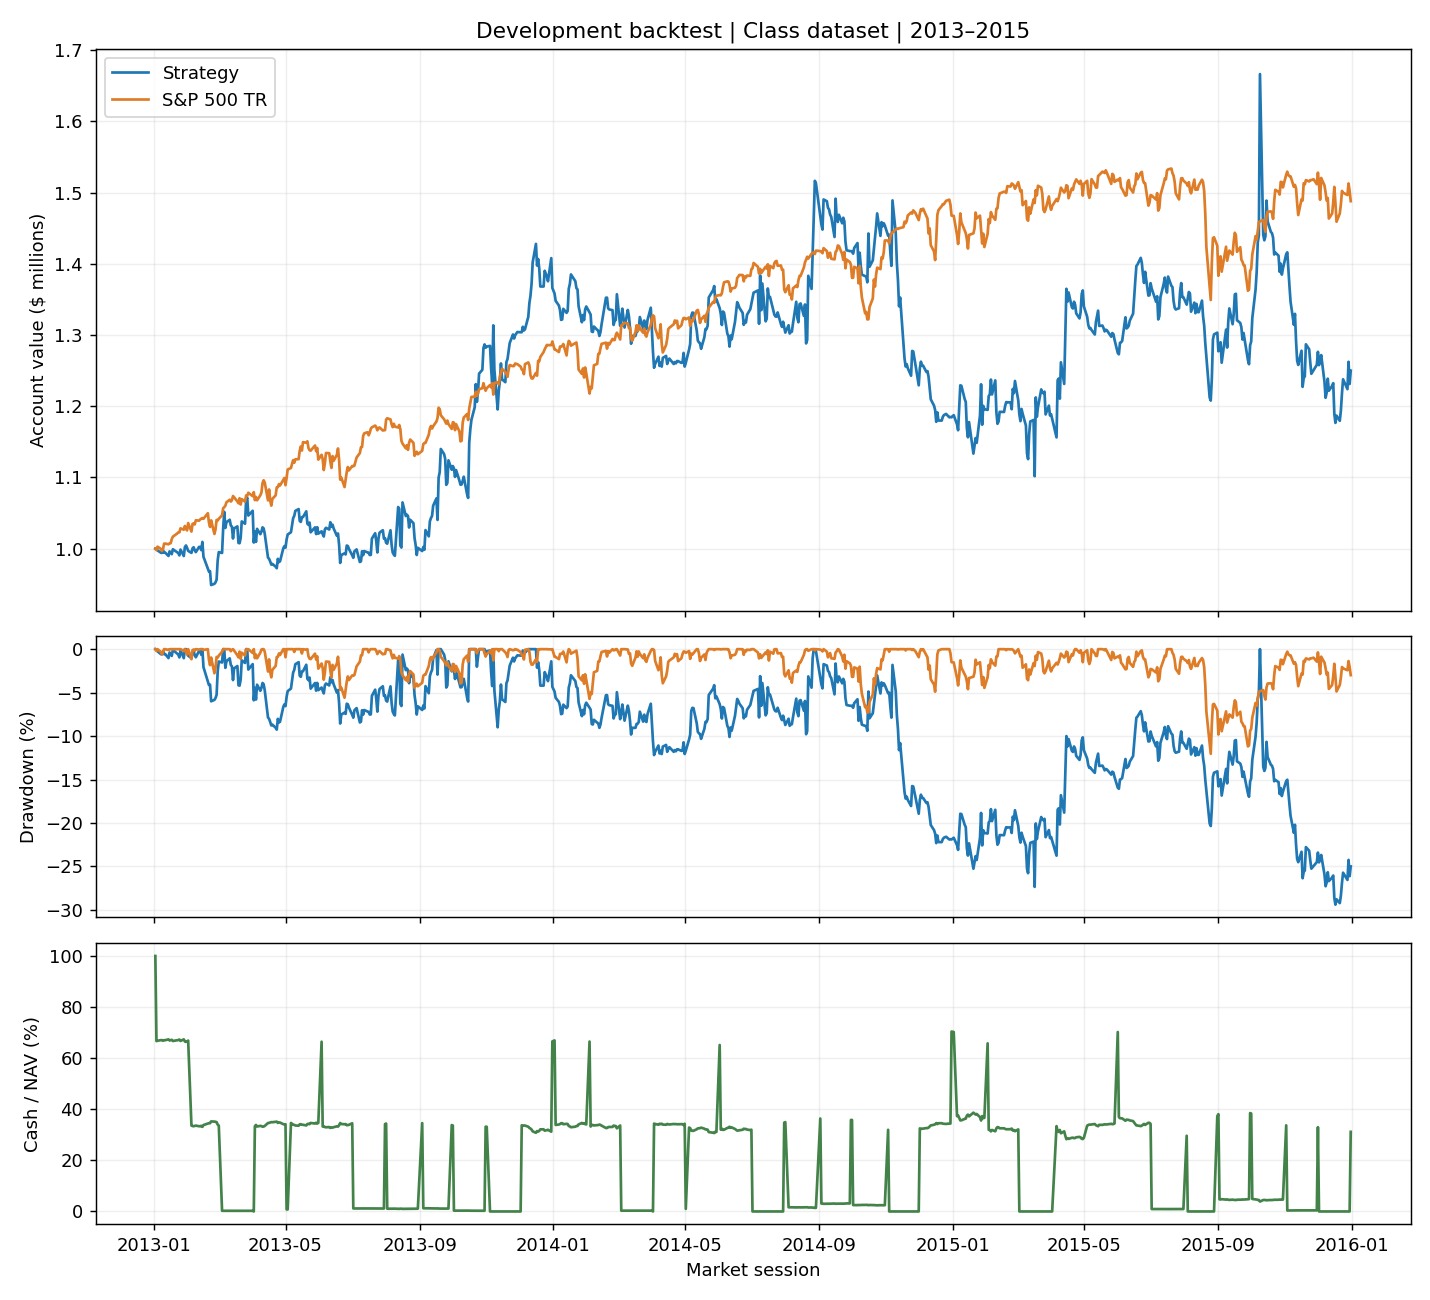

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True,
                         gridspec_kw={"height_ratios": [2, 1, 1]})
colors = ["#1f77b4", "#de7c27"]
for (name, nav), color in zip(curves.items(), colors):
    axes[0].plot(nav.index, nav / 1_000_000, label=name, color=color)
    axes[1].plot(nav.index, (nav / nav.cummax() - 1) * 100, label=name, color=color)
axes[0].set(title="Development backtest | Class dataset | 2013–2015", ylabel="Account value ($ millions)")
axes[0].legend(loc="upper left")
axes[1].set_ylabel("Drawdown (%)")
axes[2].plot(daily.date, daily.cash / daily.nav * 100, color="#43834a")
axes[2].set(ylabel="Cash / NAV (%)", xlabel="Market session")
for ax in axes:
    ax.grid(alpha=0.2)
fig.tight_layout()
plot_buffer = io.BytesIO()
fig.savefig(plot_buffer, format="png", dpi=130)
plot_png = plot_buffer.getvalue()
display(Image(data=plot_png))
plt.close(fig)

## 9. Inspect monthly NAV
NAV means **net asset value**. Here it equals cash plus the current value of all
open positions. Use the last observed market session of each month. Do not
average daily values or add them together.

```text
Daily cash + Daily open-position value -> Daily NAV
                                               |
                                               v
                            Last market session in each month
                                               |
                                               v
                             Monthly NAV table and comparison chart
```

The chart compares strategy NAV with the benchmark on the same dates. Values
include realized and unrealized results. The table also shows cash and holdings.
Monthly return is the change from the previous month-end NAV. For the first
month, use initial capital as the starting value. If the experiment starts or
ends within a month, that boundary month covers only the available sessions.

Month-end sampling can hide losses that occurred inside a month. Use the daily
drawdown chart in section 8 to assess those losses. The Sharpe ratio continues
to use daily returns; this chart does not change its calculation.

Monthly observations: 36. The saved CSV includes every month.


,cash,holdings_value,strategy_nav,benchmark_nav,strategy_monthly_return,benchmark_monthly_return
month_end_session,,,,,,
2015-01-30,"$438,320.90","$757,390.32","$1,195,711.22","$1,423,480.17",0.96%,-3.00%
2015-02-27,"$388,030.35","$847,362.87","$1,235,393.22","$1,505,292.87",3.32%,5.75%
2015-03-31,$0.00,"$1,186,848.83","$1,186,848.83","$1,481,485.66",-3.93%,-1.58%
2015-04-30,"$386,176.19","$976,349.79","$1,362,525.98","$1,495,699.91",14.80%,0.96%
2015-05-29,"$445,115.65","$848,422.44","$1,293,538.09","$1,514,932.55",-5.06%,1.29%
2015-06-30,"$470,534.75","$885,183.40","$1,355,718.15","$1,485,604.72",4.81%,-1.94%
2015-07-31,"$12,953.59","$1,340,027.66","$1,352,981.26","$1,516,731.23",-0.20%,2.10%
2015-08-31,"$486,361.18","$816,894.43","$1,303,255.61","$1,425,220.46",-3.68%,-6.03%
2015-09-30,"$495,005.42","$790,513.88","$1,285,519.30","$1,389,955.42",-1.36%,-2.47%


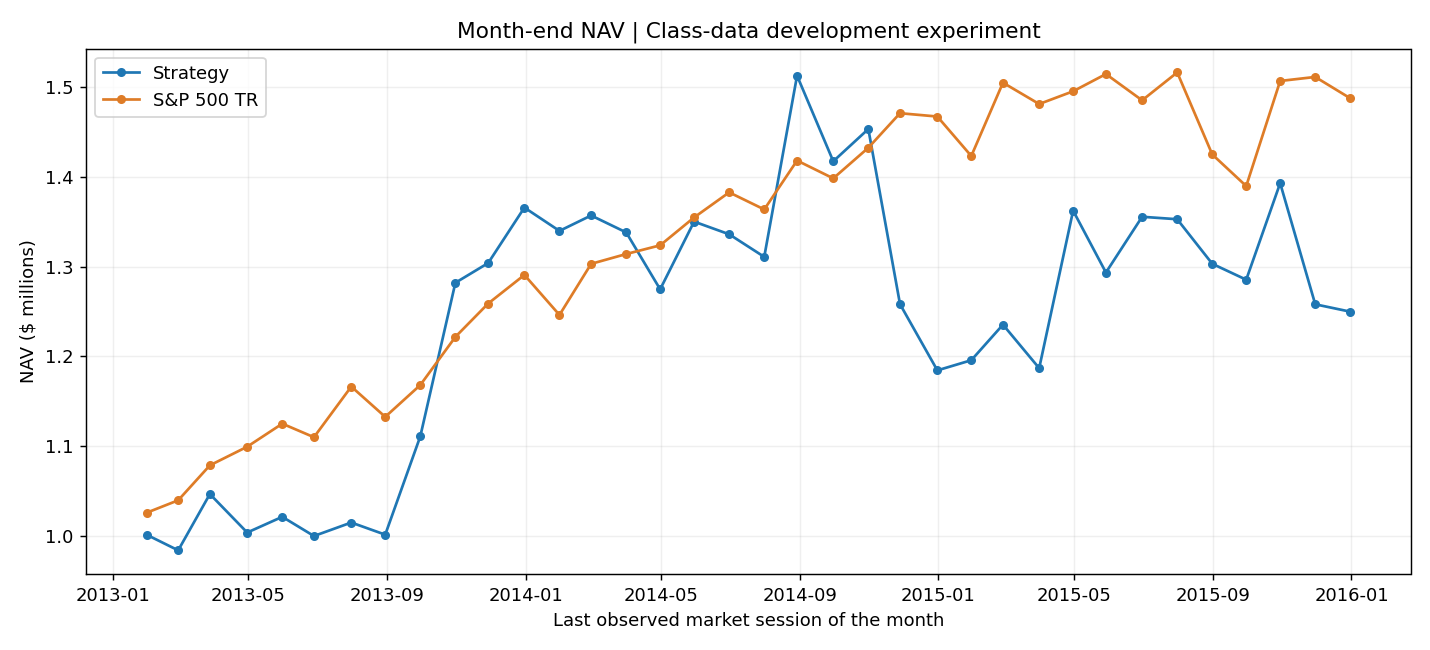

In [9]:
# Keep the actual last observed session date, including its cash and holdings.
month_end_rows = daily.groupby(daily.date.dt.to_period("M"), sort=True).tail(1)
monthly_nav = month_end_rows.set_index("date")[["cash", "holdings_value", "nav"]].copy()
monthly_nav = monthly_nav.rename(columns={"nav": "strategy_nav"})
monthly_nav["benchmark_nav"] = curves["S&P 500 TR"].reindex(monthly_nav.index)
monthly_nav["strategy_monthly_return"] = monthly_nav.strategy_nav / monthly_nav.strategy_nav.shift(1, fill_value=CONFIG.initial_cash) - 1
monthly_nav["benchmark_monthly_return"] = monthly_nav.benchmark_nav / monthly_nav.benchmark_nav.shift(1, fill_value=CONFIG.initial_cash) - 1
monthly_nav.index.name = "month_end_session"
assert monthly_nav.index.to_period("M").is_unique
np.testing.assert_allclose(monthly_nav.strategy_nav, monthly_nav.cash + monthly_nav.holdings_value)
assert np.isclose(monthly_nav.strategy_nav.iloc[-1], daily.nav.iloc[-1])

monthly_display = monthly_nav.copy()
for column in ["cash", "holdings_value", "strategy_nav", "benchmark_nav"]:
    monthly_display[column] = monthly_nav[column].map("${:,.2f}".format)
for column in ["strategy_monthly_return", "benchmark_monthly_return"]:
    monthly_display[column] = monthly_nav[column].map("{:.2%}".format)
display(monthly_display.tail(12))
print(f"Monthly observations: {len(monthly_nav)}. The saved CSV includes every month.")

monthly_fig, monthly_ax = plt.subplots(figsize=(11, 5))
monthly_ax.plot(monthly_nav.index, monthly_nav.strategy_nav / 1_000_000,
                marker="o", markersize=4, label="Strategy", color="#1f77b4")
monthly_ax.plot(monthly_nav.index, monthly_nav.benchmark_nav / 1_000_000,
                marker="o", markersize=4, label="S&P 500 TR", color="#de7c27")
monthly_ax.set(title="Month-end NAV | Class-data development experiment",
               xlabel="Last observed market session of the month", ylabel="NAV ($ millions)")
monthly_ax.grid(alpha=0.2)
monthly_ax.legend(loc="upper left")
monthly_fig.tight_layout()
monthly_buffer = io.BytesIO()
monthly_fig.savefig(monthly_buffer, format="png", dpi=130)
monthly_plot_png = monthly_buffer.getvalue()
display(Image(data=monthly_plot_png))
plt.close(monthly_fig)

## 10. Inspect decisions, realized results, and open lots
Use the decision log to explain skipped months. Use the rejection log to see
which ranked stocks failed an exposure or sector check. A missing entry quote
appears in the order log instead.

Realized profit below includes both entry and exit fees for sold lots. It excludes
the profit or loss of open lots. It is not a standalone contribution measure
for the whole portfolio. The open-lot table shows the remaining market values.

In [10]:
display(result.decisions.loc[result.decisions.reason.ne("planned")])
display(result.rejections.head(10))
if not result.orders.empty:
    display(result.orders.groupby("status").size().rename("orders").to_frame())
if not trades.empty:
    realized = trades.loc[trades.side.eq("SELL")].groupby("symbol").net_pnl.sum().sort_values()
    display(realized.rename("realized_net_profit").to_frame().head(10))
if not result.open_lots.empty:
    display(result.open_lots[["lot_id", "symbol", "entry_date", "due_date", "market_value", "unrealized_pnl"]])

,signal_date,execution_date,cash,nav,budget_cap,candidate_count,selected_count,planned_cash,symbols,reason
11,2013-12-02,2013-12-03,0.0,1.303776e+06,0.0,29,0,0.0,,no_cash
23,2014-12-01,2014-12-02,0.0,1.229299e+06,0.0,28,0,0.0,,no_cash
27,2015-04-01,2015-04-02,0.0,1.188840e+06,0.0,29,0,0.0,,no_cash


,signal_date,symbol,prediction,reason


,orders
status,
filled,165


,realized_net_profit
symbol,
APDN,-103637.336629
FCX,-73916.634595
IBM,-17119.573556
PEGY,-7147.891818
ETR,-2963.407497
SCCO,-1797.076163
GE,-642.834969
KO,1880.527998
T,2030.084156


,lot_id,symbol,entry_date,due_date,market_value,unrealized_pnl
0,156,PEGY,2015-11-03,2016-02-01,89686.137947,-4541.034491
1,157,BESS,2015-11-03,2016-02-01,84719.735459,-9507.436979
2,158,JPM,2015-11-03,2016-02-01,94500.387845,273.215407
3,159,IBM,2015-11-03,2016-02-01,92158.001161,-2069.171277
4,160,SCCO,2015-11-03,2016-02-01,87483.360764,-6743.811674
5,161,PEGY,2015-12-02,2016-03-01,79068.060530,-5162.474361
6,162,APDN,2015-12-02,2016-03-01,82491.467096,-1739.067796
7,163,BESS,2015-12-02,2016-03-01,94664.687066,10434.152174
8,164,FCX,2015-12-02,2016-03-01,72709.015309,-11521.519583
9,165,IBM,2015-12-02,2016-03-01,82896.224331,-1334.310561


## 11. Analyze the strategy
Read return and risk together. A positive return alone does not show that the
strategy improved on the benchmark. The interpretation below uses this run's
outputs. It updates when the notebook runs again.

**Sharpe ratio:** Subtract the daily risk-free return from each daily portfolio
return. Divide the mean excess return by the sample standard deviation of daily
returns. Multiply by the square root of 252 to annualize the result.

```text
Daily NAV -> Daily return -> Subtract daily risk-free return -> Mean excess return
                     |                                               |
                     v                                               v
          Daily return standard deviation ---------------------> Sharpe x sqrt(252)
```

In formula form: `annualized Sharpe = mean(daily excess return) / std(daily return) * sqrt(252)`.
The annual risk-free rate comes from `CONFIG.risk_free_rate` (2% in the baseline).
Convert it to a daily rate with `(1 + annual rate)**(1/252) - 1`.
Cash still earns zero. A higher Sharpe means more average excess return per unit
of return variability on this sample. It is not a probability of profit or a
measure of the largest possible loss. A negative Sharpe means average daily
return was below the daily risk-free rate. A constant return series has no
defined Sharpe in this implementation.

The following cash and fee figures describe the run. They do not isolate the
cause of underperformance. Test one change at a time before making that claim.

In [11]:
from IPython.display import Markdown

strategy_metrics = metrics.loc["Strategy"]
benchmark_metrics = metrics.loc["S&P 500 TR"]
strategy_months = monthly_nav.strategy_monthly_return
best_month = strategy_months.idxmax()
worst_month = strategy_months.idxmin()
positive_months = int(strategy_months.gt(0).sum())
average_cash_weight = (daily.cash / daily.nav).mean()
skipped_months = int(result.decisions.reason.ne("planned").sum())
cash_skips = int(result.decisions.reason.eq("no_cash").sum())
total_fees = daily.fees.sum()
value_gap = strategy_metrics.final_value - benchmark_metrics.final_value
return_gap = strategy_metrics.total_return - benchmark_metrics.total_return

strategy_sharpe = strategy_metrics.daily_Sharpe
benchmark_sharpe = benchmark_metrics.daily_Sharpe
if np.isfinite(strategy_sharpe) and np.isfinite(benchmark_sharpe):
    comparison = "higher" if strategy_sharpe > benchmark_sharpe else "lower" if strategy_sharpe < benchmark_sharpe else "equal"
    sharpe_reading = f"The strategy's Sharpe was {comparison} than the benchmark's." if comparison != "equal" else "The two Sharpe ratios were equal."
else:
    sharpe_reading = "At least one Sharpe ratio is undefined. Do not rank the portfolios by Sharpe."
drawdown_reading = "larger" if strategy_metrics.max_drawdown < benchmark_metrics.max_drawdown else "smaller" if strategy_metrics.max_drawdown > benchmark_metrics.max_drawdown else "equal"
outcome = "above" if value_gap > 0 else "below" if value_gap < 0 else "equal to"

analysis_text = f"""### Interpretation of the current run

**Return.** The strategy returned **{strategy_metrics.total_return:.2%}**, compared with
**{benchmark_metrics.total_return:.2%}** for the benchmark. It finished {outcome} the
benchmark. The signed difference was **${value_gap:,.2f}**, or **{return_gap * 100:.2f}
percentage points** of total return. Strategy CAGR was **{strategy_metrics.CAGR:.2%}**;
benchmark CAGR was **{benchmark_metrics.CAGR:.2%}**.

**Sharpe ratio.** The annualized Sharpe from daily returns was **{strategy_sharpe:.3f}**
for the strategy and **{benchmark_sharpe:.3f}** for the benchmark. {sharpe_reading}
This comparison uses the same dates and a **{CONFIG.risk_free_rate:.1%}** annual risk-free rate.

**Drawdown.** The strategy's maximum drawdown was **{strategy_metrics.max_drawdown:.2%}**.
The benchmark's was **{benchmark_metrics.max_drawdown:.2%}**. The strategy's peak-to-trough
decline was {drawdown_reading}. These figures use daily NAV, not the monthly chart.

**Monthly results.** The strategy had **{positive_months} positive months out of
{len(strategy_months)} observed months**. Its best month was **{best_month:%Y-%m}**
at **{strategy_months.loc[best_month]:.2%}**. Its worst month was **{worst_month:%Y-%m}**
at **{strategy_months.loc[worst_month]:.2%}**. The first and last months follow the
selected experiment dates.

**Cash and fees.** The average daily cash weight was **{average_cash_weight:.2%}**.
The strategy skipped **{skipped_months} of {len(result.decisions)} monthly purchase
decisions**, including **{cash_skips}** with no cash. It paid **${total_fees:,.2f}** in
entry and exit fees. Fees reduce returns. Cash changes market exposure. These
figures alone do not explain the whole return gap.

**Conclusion.** Use this result as the development baseline. Inspect the trade
record before changing features. Compare one change at a time with the same
dates, fees, and trading rules. These results use the small class dataset;
they do not establish performance on the final test or in live trading.
"""
display(Markdown(analysis_text))

### Interpretation of the current run

**Return.** The strategy returned **24.98%**, compared with
**48.78%** for the benchmark. It finished below the
benchmark. The signed difference was **$-237,997.51**, or **-23.80
percentage points** of total return. Strategy CAGR was **7.74%**;
benchmark CAGR was **14.20%**.

**Sharpe ratio.** The annualized Sharpe from daily returns was **0.332**
for the strategy and **0.950** for the benchmark. The strategy's Sharpe was lower than the benchmark's.
This comparison uses the same dates and a **2.0%** annual risk-free rate.

**Drawdown.** The strategy's maximum drawdown was **-29.39%**.
The benchmark's was **-12.04%**. The strategy's peak-to-trough
decline was larger. These figures use daily NAV, not the monthly chart.

**Monthly results.** The strategy had **17 positive months out of
36 observed months**. Its best month was **2013-10**
at **15.42%**. Its worst month was **2014-11**
at **-13.44%**. The first and last months follow the
selected experiment dates.

**Cash and fees.** The average daily cash weight was **18.33%**.
The strategy skipped **3 of 36 monthly purchase
decisions**, including **3** with no cash. It paid **$24,502.98** in
entry and exit fees. Fees reduce returns. Cash changes market exposure. These
figures alone do not explain the whole return gap.

**Conclusion.** Use this result as the development baseline. Inspect the trade
record before changing features. Compare one change at a time with the same
dates, fees, and trading rules. These results use the small class dataset;
they do not establish performance on the final test or in live trading.


## 12. Save the experiment
Keep the generated files outside Git. Save the daily account, trade and order
records, decisions, open lots, metrics, settings, and chart in the experiment
folder. Reusing the same experiment name overwrites that run's files.

The manifest records the database and forecast checksums. It also records the
model settings and the backtester code checksum. These fields identify the
inputs used by this run.

Save the month-end NAV table, monthly chart, and computed strategy analysis too.

In [12]:
assert digest(DATABASE) == database_hash
assert digest(MODEL_DIR / "validation_forecasts.csv") == forecast_hash
if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    for name in ["daily", "trades", "orders", "decisions", "rejections", "open_lots"]:
        getattr(result, name).to_csv(OUTPUT_DIR / f"{name}.csv", index=False)
    curves.to_csv(OUTPUT_DIR / "equity_curves.csv")
    metrics.to_csv(OUTPUT_DIR / "performance.csv")
    monthly_nav.to_csv(OUTPUT_DIR / "monthly_nav.csv")
    (OUTPUT_DIR / "monthly_nav.png").write_bytes(monthly_plot_png)
    (OUTPUT_DIR / "strategy_analysis.md").write_text(analysis_text, encoding="utf-8")
    (OUTPUT_DIR / "development_returns.png").write_bytes(plot_png)
    manifest = {
        "start": START, "end": END, "scope": "class-data development only",
        "config": asdict(CONFIG), "monthly_signal": "first market session close",
        "entry": "next market session close", "cash_interest": 0.0,
        "missing_entry": "cancel order", "missing_held_quote": "stop",
        "short_candidate_list": "skip month", "exposure_checks": "signal-close plan after entry fees",
        "database_sha256": database_hash, "forecasts_sha256": forecast_hash,
        "backtester_sha256": digest(HW_DIR / "strategy_backtest.py"),
        "model_settings": model_settings,
    }
    (OUTPUT_DIR / "experiment.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    print(f"Saved: {OUTPUT_DIR.relative_to(ROOT)}")
print("PASS: database and saved model forecasts are unchanged.")

Saved: Homeworks\HW4\Mauricio_Gutierrez\outputs\backtesting\ridge_monthly_baseline
PASS: database and saved model forecasts are unchanged.


## Use this result for the next experiment
1. Read the benchmark comparison.
2. Inspect the largest losses and skipped decisions.
3. Choose one feature, model setting, or strategy rule to change.
4. Save the changed run under a new experiment name.
5. Compare it on the same development dates.

Do not attribute a return change to a feature if you also changed trading rules.
Keep the final test closed while you choose settings. A later full-dataset run
needs a memory plan and explicit treatment of any held-stock price gaps. A
missing price stops this implementation; it does not silently remove the stock.

The model forecasts 90-day gross returns. Actual portfolio returns also depend
on cash timing, fees, repeated purchases, and exposure limits. A better model
error score does not guarantee a better portfolio result.

**Sources and assistance:** The interface structure follows the ideas explained
in [Lecture 8](../../../Lectures/Lecture%208/1_backtesting.ipynb). The target and
accounting rules follow [HW4](../../../Lectures/Lecture%208/hw4.md). This is our
own execution implementation. Codex helped write, document, and test it.